In [1]:
import scanpy as sc
import seaborn as sns
from tqdm import tqdm
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.amp import autocast, GradScaler

from dataprocess.h5a import H5ADTokenizer
from dataprocess.genepep import GenePepExtractor
from model.const import set_species_context
from model import data
import model.resa as resa
import model.swav as swav
import model.utils as utils
import model.mmd as mmd
import model.lr_schedule as lr_sche

In [2]:
organ='cortex1'
species_list=['homo_sapiens','Mus_musculus','Callithrix_jacchus','Petromyzon_marinus','Maylandia_zebra']
species_to_adata = {
    k: sc.read_h5ad(f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/h5data/{organ}/{k}.h5ad") for k in species_list
}

In [3]:
species_to_embed_file = {
    k:f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/esm_embedding/{organ}/{k}.avg.embeddings" for k in species_list
}

In [4]:
species_dict=set_species_context(species_to_adata)
token_species_dict={v:k for k,v in species_dict.items()}

In [5]:
tokenized = H5ADTokenizer(
    species_to_adata,
    species_to_embed_file,
).process_species_adata()

100%|██████████| 33383/33383 [00:01<00:00, 31761.78it/s]


In [6]:
species_to_reps={
    k:'X_pca' for k in species_list
}

In [7]:
train_loader, test_loader = data.prepare_multispecies_dataloaders(
    tokenized,
    batch_size=512,
    species_to_reps=species_to_reps,
    batch_species=5,
)

homo_sapiens: X_pca
Mus_musculus: X_pca
Callithrix_jacchus: X_pca
Petromyzon_marinus: X_pca
Maylandia_zebra: X_pca


In [8]:
d_model=120
scale=4
input_size=50
latent_size=64
num_layers=1
n_clusters=100000
net=resa.ReSA(species_to_embed_file,d_model,input_size,latent_size,num_layers,n_clusters,scale=scale,)

In [9]:
def train_epoch(net,train_loader,loss_fn,loss_fn1,optimizer,scaler,device,current_temp,scheduler,ml_weight=1.0):
    net.train()
    metrics=utils.Accumulator(4)
    pbar=tqdm(train_loader,desc='Processing')
    for _,batch in enumerate(pbar):
        optimizer.zero_grad(set_to_none=True)

        data,adata,sp=batch
        data = data.to(device, non_blocking=True)
        adata = adata.float().to(device, non_blocking=True)
        sp = sp.to(device, non_blocking=True)

        with autocast('cuda'):
            sl = torch.tensor(0.0, device=device)
            protein_features,gene_features,logit_scale=net(adata,data,sp,)
            species_ids = torch.unique(sp).tolist()
            #for i in torch.unique(sp):
            for s in species_ids:
                mask = (sp == s)

                indices = torch.nonzero(mask).squeeze(1)
                protein_features_i = torch.index_select(protein_features, 0, indices)
                gene_features_i = torch.index_select(gene_features, 0, indices)
                sl += loss_fn(protein_features_i, gene_features_i, logit_scale,)
                #sl += loss_fn(protein_features_i, gene_features_i, logit_scale,)
            ml=loss_fn1(protein_features,sp)
            loss=sl+ml*ml_weight

        scaler.scale(loss).backward()
        if net.transformer.embed.gene_embed.weight.grad is not None:
            #net.transformer.embed.gene_embed.weight.grad[3:-1] = 0
            net.transformer.embed.gene_embed.weight.grad[4:] = 0
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(net.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        if scheduler:
            scheduler.step()
        lr=optimizer.param_groups[0]['lr']
        pbar.set_description(f"loss:{loss.detach().item():.4f},sl:{sl.detach().item():.8f},ml:{ml.detach().item():.8f},lr:{lr:.8f}")
        metrics.add(loss.detach().item() * len(sp), sl.detach().item() * len(sp),ml.detach().item() * len(sp), len(sp))

    return {'loss':metrics[0] / metrics[3],'sl':metrics[1] / metrics[3],'ml':metrics[2] / metrics[3],}

def train(net,train_loader,test_loader,epochs,lr,species_to_h5,net_path,temp,ml_weight):
    def init_weights(m):
        if type(m) == nn.Linear or type(m) == nn.Conv1d:
            nn.init.xavier_uniform_(m.weight)
    net.apply(init_weights)
    print('init done')

    device =torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print('training on', device)
    net.to(device)

    loss_fn=resa.MultiScaleReSALoss()#swav.WeightedMultiScaleATACKNNLoss()#
    loss_fn1=mmd.MMMD(kernel_type='rbf',each=True)#mmd.MSampleLoss(each=True)#
    optimizer = torch.optim.AdamW(net.parameters(), lr=lr,fused=True)
    scheduler = lr_sche.CosineAnnealingWarmupRestarts(
        optimizer,
        first_cycle_steps=2000,   # 一个周期 2000 batch
        cycle_mult=1,             # 不增加周期长度
        max_lr=lr*1.5,            # 最大 lr 稍高
        min_lr=1e-6,
        warmup_steps=400,         # 前 400 batch 线性升到 max_lr
        gamma=0.8
    )
    early_stopping = utils.EarlyStopping(
        patience=10,               # 连续5个epoch指标不提升就停止
        verbose=True, 
        path=net_path, # 保存的文件名
        mode='min'                # 如果监控的是准确率，这里改用 'max'
    )
    scaler = GradScaler('cuda')
    cr_ml_weight=0.0
    warm_epoch=5
    try:
        for epoch in range(epochs):
            print(f"epoch:{epoch},")
            print(f"Temp: {temp}")
            if epoch>=warm_epoch:
                cr_ml_weight=ml_weight
            losses=train_epoch(net,train_loader,loss_fn,loss_fn1,optimizer,scaler,device,temp,scheduler,cr_ml_weight)
            current_lr = optimizer.param_groups[0]['lr']
            print(f"lr:{current_lr},")
            print(f'{losses}')
            if epoch>=warm_epoch:
                early_stopping(losses['loss'],net)
                if early_stopping.early_stop:
                    print("====== Early stopping triggered! ======")
                    break
            if epoch ==epochs-1:
                torch.save(net.state_dict(), net_path)
                print(f'saving weight in {net_path}')
                break
    except KeyboardInterrupt:
        #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
        torch.save(net.state_dict(), net_path)
        print(f'saving weight in {net_path}')
        

In [10]:
net_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/pth/ReSA_{organ}.pth'
species_to_h5=tokenized
epochs=100
lr=1e-3
#train(net,train_loader,test_loader,epochs,lr,species_to_h5,net_path,temp=0.2,ml_weight=1.0)

In [11]:
net_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/pth/ReSA_{organ}.pth'
net.load_state_dict(torch.load(net_path,weights_only=True))

<All keys matched successfully>

computing PCA
    with n_comps=25
    finished (0:00:00)
Running MOT_Correction by 'inferred_species' -> adata.obsm['X_mot']
X_mot shape: (129841, 25)
computing neighbors


/mnt/public5/panguanyu/environment/mconda3/miniconda3/envs/crs_env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:48)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:01:39)


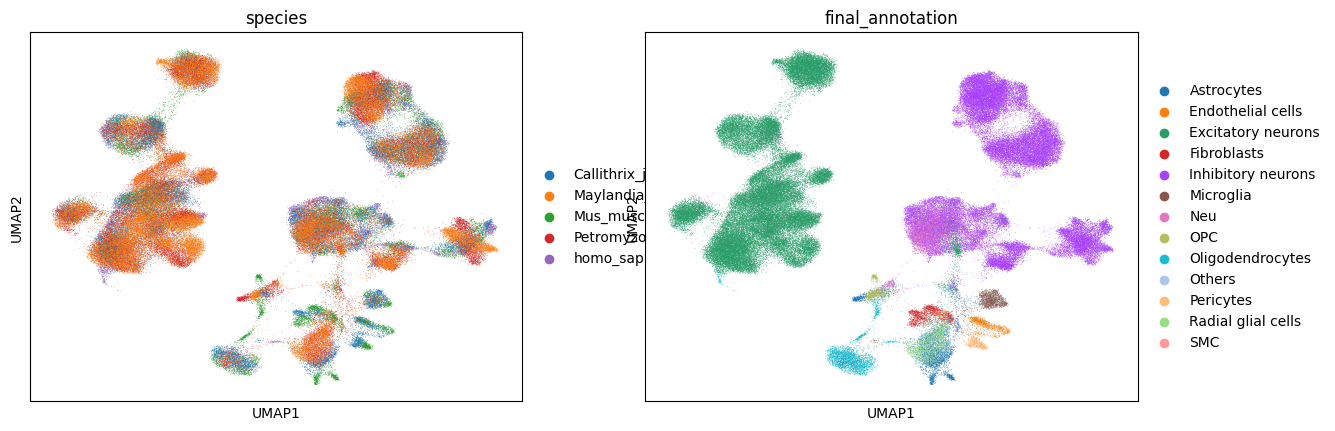

In [12]:
import importlib
import model.evaluate
importlib.reload(model.evaluate)
from model.evaluate import evaluate_integration

integrated_adata = evaluate_integration(
    net,
    test_loader,
    species_to_adata=tokenized,
    #metadata_columns=["final_annotation","Org_celltype"],
    # 如果不同物种列名不一样，改用：
    species_to_metadata_columns={
        "one":["celltype","final_annotation"],
        "homo_sapiens": ["Org_celltype", "final_annotation"],
        "Mus_musculus": ["Org_celltype", "final_annotation"],
        "Callithrix_jacchus":["Org_celltype","final_annotation"],
        "Petromyzon_marinus":["Org_celltype","final_annotation"],
        "Maylandia_zebra":["Org_celltype","final_annotation"]
    },
    embedding="protein",
    use_mot_correction=True,
    correction_by="inferred_species",
    correction_kwargs={
        "max_rounds": 10,
        "n_clusters": 100,
        "assignment_mode": "sinkhorn",
    },
    umap_colors=["species", "final_annotation"],
    umap_min_dist=0.0,
    comatrix_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/comatrix/{organ}.npz'
)

In [13]:
integrated_adata

AnnData object with n_obs × n_vars = 129841 × 64
    obs: 'species', 'celltype', 'final_annotation', 'inferred_species_token', 'inferred_species'
    uns: 'pca', 'neighbors', 'umap', 'species_colors', 'final_annotation_colors'
    obsm: 'X_pca', 'X_mot', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [14]:
integrated_adata.write('/mnt/public5/panguanyu/cross_species/code/sypy/umap_results/figure3/cortex/hresa_1_64_1.h5ad')

In [15]:
integrated_adata.obs["pcelltype"] = (
    integrated_adata.obs["celltype"]
    .astype(str)
    .str.replace(r"^(\d+)\.\d+_", r"\1_", regex=True)
)

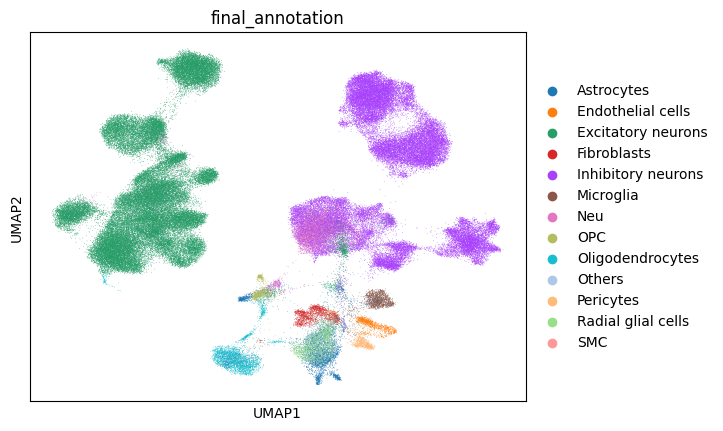

In [40]:
sc.pl.umap(integrated_adata,color=['final_annotation',])

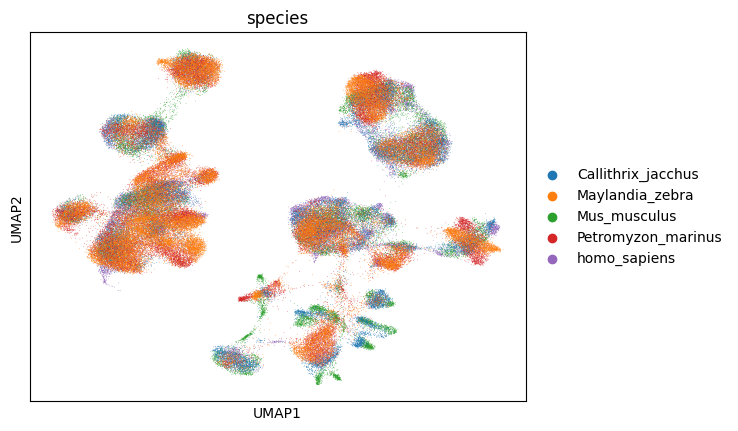

In [17]:
sc.pl.umap(integrated_adata,color=['species',])

In [18]:
hmc_adata=integrated_adata[integrated_adata.obs['species'].isin(['homo_sapiens','Mus_musculus','Callithrix_jacchus'])]

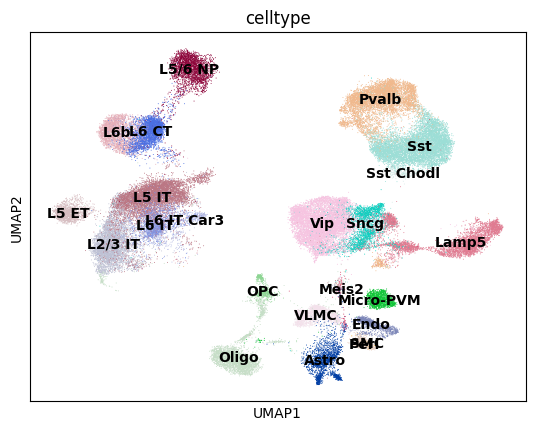

In [42]:
sc.pl.umap(
    hmc_adata,
    color=["celltype", ],
    legend_loc="on data",
    ncols=2,
    wspace=0.5,
)

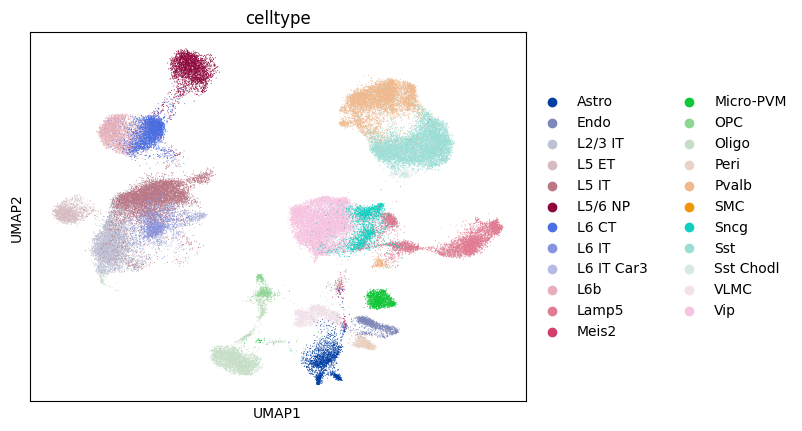

In [41]:
sc.pl.umap(
    hmc_adata,
    color=["celltype", ],
)

In [20]:
pm_adata=integrated_adata[integrated_adata.obs['species'].isin(['Petromyzon_marinus','Maylandia_zebra'])]

In [21]:
pm_adata.obs["pcelltype"] = (
    pm_adata.obs["celltype"]
    .astype(str)
    .str.replace(r"^(\d+)\.\d+_", r"\1_", regex=True)
)

/tmp/ipykernel_29028/4124942137.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  pm_adata.obs["pcelltype"] = (


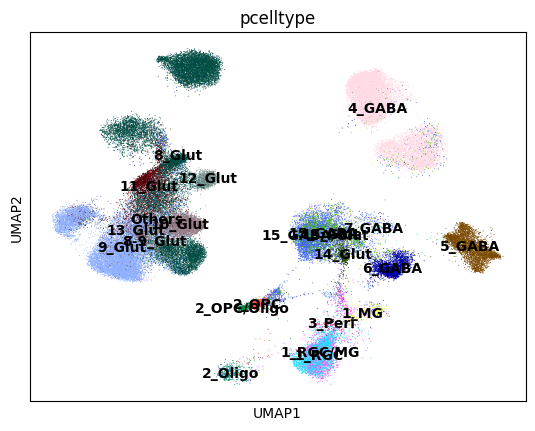

In [43]:
sc.pl.umap(
    pm_adata,
    color=["pcelltype", ],
    legend_loc="on data",
    ncols=2,
    wspace=0.5,
)

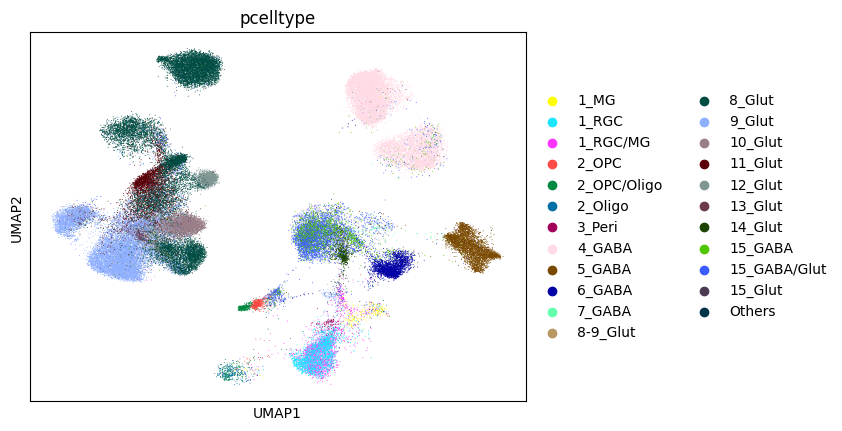

In [39]:
sc.pl.umap(
    pm_adata,
    color=["pcelltype", ],
)

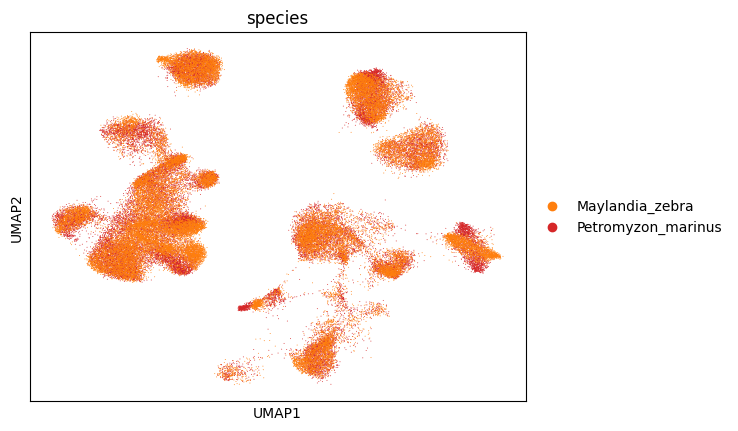

In [23]:
sc.pl.umap(pm_adata,color=['species',])

In [24]:
Counter(pm_adata.obs['pcelltype'])

Counter({'8_Glut': 15819,
         '9_Glut': 11705,
         '4_GABA': 11141,
         '15_GABA/Glut': 5099,
         '10_Glut': 3848,
         '5_GABA': 3715,
         '11_Glut': 3170,
         '6_GABA': 2262,
         '1_RGC/MG': 2089,
         '1_RGC': 1848,
         '15_GABA': 1740,
         '12_Glut': 1160,
         '13_Glut': 622,
         '2_OPC/Oligo': 614,
         '14_Glut': 602,
         '2_OPC': 411,
         '8-9_Glut': 219,
         '15_Glut': 209,
         '1_MG': 182,
         '2_Oligo': 180,
         'Others': 164,
         '3_Peri': 144,
         '7_GABA': 114})

In [25]:
Counter(hmc_adata.obs['celltype'])

Counter({'Vip': 7985,
         'Sst': 7780,
         'L5 IT': 6660,
         'Pvalb': 6242,
         'L2/3 IT': 4746,
         'Lamp5': 4550,
         'Oligo': 3347,
         'L6 CT': 3081,
         'L5/6 NP': 2615,
         'L6b': 2410,
         'Sncg': 2186,
         'Astro': 1867,
         'L6 IT': 1767,
         'VLMC': 1646,
         'Micro-PVM': 1354,
         'L5 ET': 1306,
         'Endo': 1104,
         'Peri': 762,
         'OPC': 595,
         'L6 IT Car3': 405,
         'Sst Chodl': 248,
         'Meis2': 109,
         'SMC': 19})

### Map `pm_adata` cell types to the HMC annotation system

The two annotations are not a predefined one-to-one ontology: `pcelltype` contains broad fish/lamprey classes, whereas the HMC labels contain finer mammalian cortical subtypes. The mapping below is therefore inferred from cross-species neighbours in the integrated `X_mot` space. `mapping_confidence` is the fraction of cells in each PM group supporting its most frequent HMC label; inspect low-confidence rows rather than treating them as exact biological equivalences.

In [26]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

# Work on copies because both objects were created by AnnData slicing.
pm_adata = pm_adata.copy()
hmc_adata = hmc_adata.copy()

# Use mammalian cells as the labelled reference in the aligned latent space.
knn = KNeighborsClassifier(n_neighbors=30, weights="distance", n_jobs=-1)
knn.fit(hmc_adata.obsm["X_mot"], hmc_adata.obs["celltype"].astype(str))
pm_adata.obs["hmc_celltype_knn"] = knn.predict(pm_adata.obsm["X_mot"])

# Summarise the cell-level predictions into one mapping per PM annotation.
mapping_counts = pd.crosstab(
    pm_adata.obs["pcelltype"].astype(str),
    pm_adata.obs["hmc_celltype_knn"].astype(str),
)
mapping_table = pd.DataFrame({
    "mapped_hmc_celltype": mapping_counts.idxmax(axis=1),
    "mapping_confidence": mapping_counts.max(axis=1) / mapping_counts.sum(axis=1),
    "n_cells": mapping_counts.sum(axis=1),
}).sort_values(["mapping_confidence", "n_cells"], ascending=[False, False])

pm_to_hmc = mapping_table["mapped_hmc_celltype"].to_dict()
pm_adata.obs["mapped_celltype"] = (
    pm_adata.obs["pcelltype"].astype(str).map(pm_to_hmc).astype("category")
)
mapping_table

,mapped_hmc_celltype,mapping_confidence,n_cells
pcelltype,,,
5_GABA,Lamp5,0.990310,3715
12_Glut,L5 IT,0.952586,1160
2_Oligo,Oligo,0.938889,180
2_OPC,OPC,0.914842,411
14_Glut,Vip,0.833887,602
15_GABA,Vip,0.806897,1740
1_RGC,Astro,0.771645,1848
11_Glut,L5 IT,0.741009,3170
15_GABA/Glut,Vip,0.740733,5099


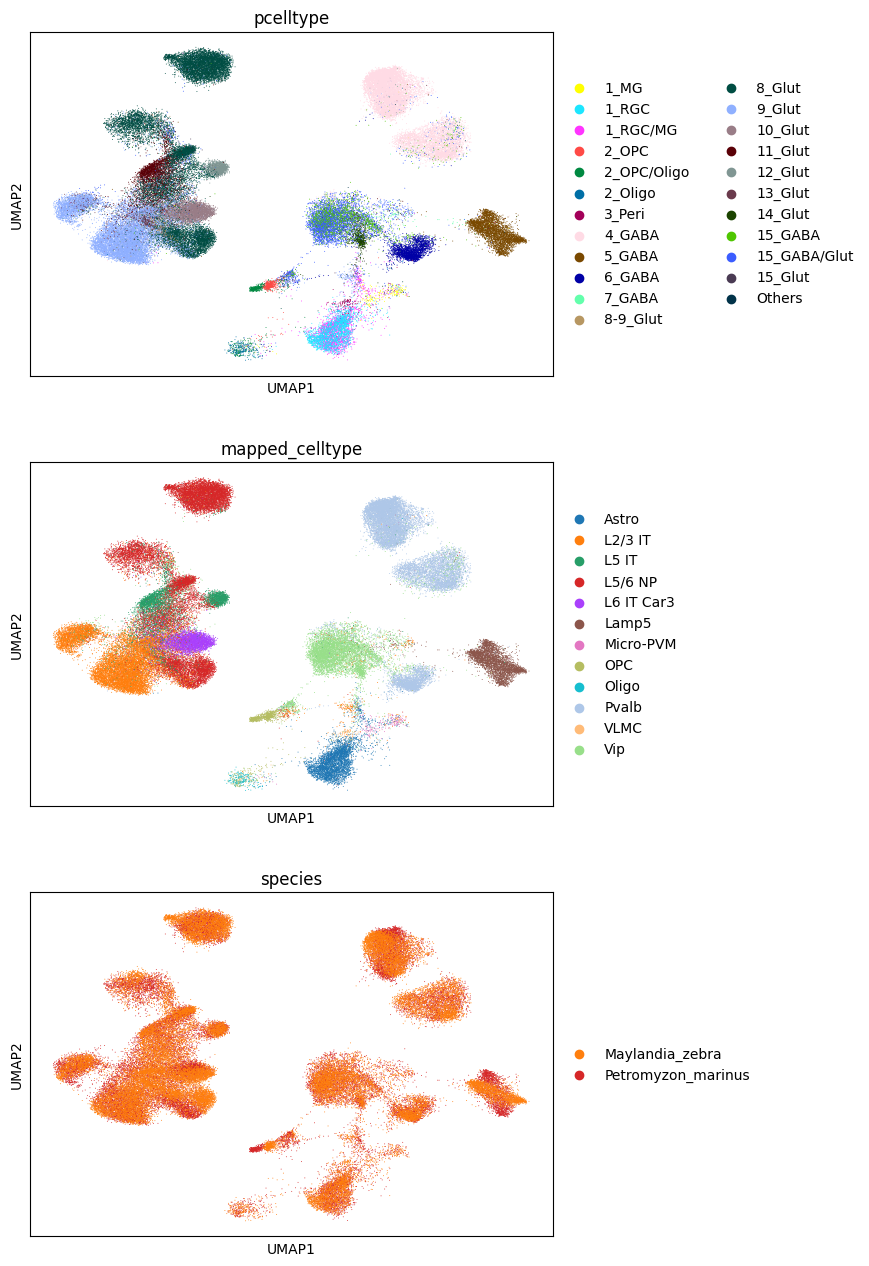

In [27]:
sc.pl.umap(pm_adata, color=["pcelltype", "mapped_celltype", "species"], ncols=1)

In [28]:
from torch.utils.data import DataLoader
import numpy as np
from model.mot_correction import load_comatrix
def gene_embed_cell_color(species_to_embed_file,species_genes,species_to_dataset,net,device,batch_size,comatrix_path):
    net.transformer.embed.gene_id(species_to_embed_file)
    net.to(device)
    net.eval()
    #assert set(species_genes.keys())==set(species_to_dataset.keys())
    embeddings=[]
    gene_list=[]
    cells=[]
    sps=[]
    for species in species_genes:
        genes=species_genes[species]
        gene_tokens=[net.transformer.embed.species_gene_id_map[species][gene] for gene in genes]
        raw_map=net.transformer.embed.species_gene_id_map[species]
        token_to_gene_name = {v: k for k, v in raw_map.items()}
        dataset=species_to_dataset[species]
        test_loader=DataLoader(dataset,batch_size=batch_size,shuffle=False,collate_fn=data.h5labelcollate_fn,)

        pbar=tqdm(test_loader,desc='Processing')
        for i,batch in enumerate(pbar):
            with torch.no_grad():
                input_ids,adata,sp,y=batch
                adata=adata.to(device, non_blocking=True)
                input_ids=input_ids.to(device, non_blocking=True)
                sp = sp.to(device, non_blocking=True)
                with autocast('cuda'):
                    attn_embeddings=net.contextual_embed(input_ids,sp)
                batch_embeddings = []
                batch_gene=[]
                batch_cells=[]
                batch_sps=[]
                for gene_token in gene_tokens:
                    token_pos=(input_ids==gene_token)
                    for b in range(input_ids.shape[0]):
                        pos = token_pos[b]
                        emb = attn_embeddings[b][pos]
                        H = attn_embeddings.shape[2]
                        if emb.shape[0] == 0:
                            batch_embeddings.append(torch.zeros(H, device=device))
                        else:
                            batch_embeddings.append(emb.mean(0))
                        batch_cells.append(int(y[b]))
                        batch_gene.append(token_to_gene_name[gene_token])
                        batch_sps.append(token_species_dict[int(sp[b])])
                token_embeddings = torch.stack(batch_embeddings, dim=0)
            embeddings.append(token_embeddings.cpu())
            gene_list+=batch_gene
            cells+=list(test_loader.dataset.le.inverse_transform(batch_cells))
            sps+=batch_sps
    embeddings=torch.cat(embeddings,dim=0)
    #embeddings=F.normalize(embeddings,p=2,dim=1).numpy()
    embeddings=embeddings.numpy()
    types=['gene']*len(embeddings)

    
    adata=sc.AnnData(embeddings)
    adata.obs['cell_type']=cells
    adata.obs['gene']=gene_list
    adata.obs['sp']=sps
    print(adata.shape)
    mask = ~(np.all(adata.X == 0, axis=1))  # True 表示不是全零
    adata = adata[mask].copy()  # 保留非全零的行
    adata.obsm['X_pca_harmony']=load_comatrix(comatrix_path,adata.X.T,adata.obs['sp'])
    print(adata.shape)
    sc.pp.neighbors(adata, use_rep='X_pca_harmony')
    sc.tl.umap(adata)
    n = adata.obs['cell_type'].nunique()
    colors = sns.color_palette("tab20") + sns.color_palette("tab20b") + sns.color_palette("tab20c")
    colors = colors[:n]
    return adata
    

In [29]:
species_genes={
    'homo_sapiens':['DSCAM'],
    'Mus_musculus':['DSCAML1']
}
gene_cell_column='final_annotation'
species_to_dataset={}
for species,adata in species_to_adata.items():
    if species in species_genes:
        print(f"loading {species}")
        #adata=sc.read_h5ad(h5_file)
        species_to_dataset[species]=data.AnndataLabelDataset(adata,species,cell_column=gene_cell_column,X_rep='X_pca')

device =torch.device('cuda' if torch.cuda.is_available() else 'cpu')

loading homo_sapiens
loading Mus_musculus


In [30]:
gene_adata=gene_embed_cell_color(species_to_embed_file,species_genes,species_to_dataset,net,device,
                                 batch_size=512,comatrix_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/comatrix/{organ}.npz')

Processing: 100%|██████████| 43/43 [00:03<00:00, 12.58it/s]


(41381, 64)
(30579, 64)
computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:04)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:30)


In [31]:
gene_adata

AnnData object with n_obs × n_vars = 30579 × 64
    obs: 'cell_type', 'gene', 'sp'
    uns: 'neighbors', 'umap'
    obsm: 'X_pca_harmony', 'X_umap'
    obsp: 'distances', 'connectivities'

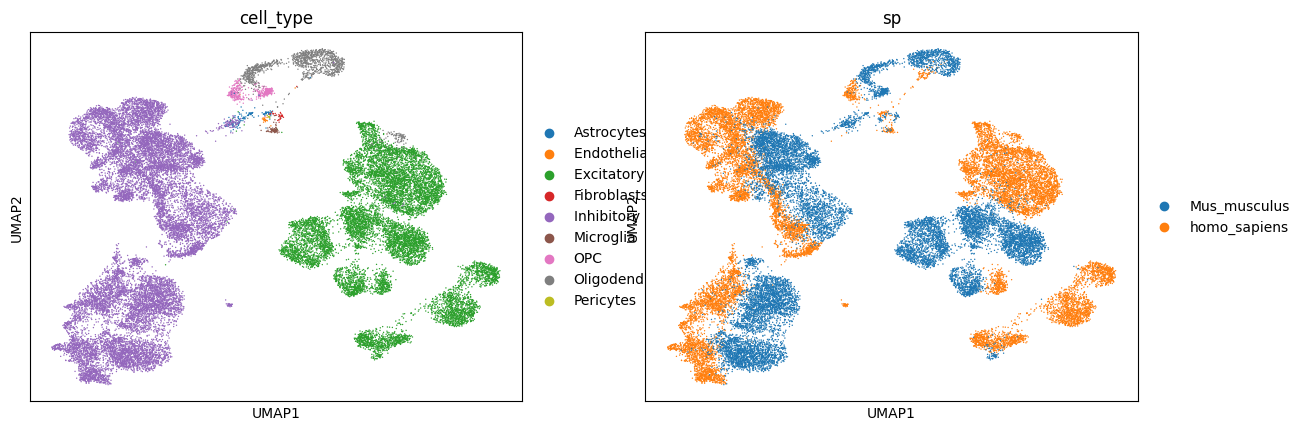

In [32]:
sc.pl.umap(gene_adata,color=['cell_type','sp'])